# Sleep Cycle Prediction Using Machine Learning
## Sleep-EDF-20 EEG sleep-stage classification

This notebook uses the preprocessed `.npz` files already present in `archive (11)`. Each row is one 30-second, 100 Hz Fpz-Cz EEG epoch with a provided stage code. The model target is one of **Wake, N1, N2, N3, REM**. Stage IDs are mapped as 0→Wake, 1→N1, 2→N2, 3→N3, 4→REM; the measured counts match the standard Sleep-EDF-20 stage distribution. No lifestyle CSV is used.

We extract fixed signal features for traditional ML, split by subject, tune with grouped folds on training subjects, and reserve held-out subjects for final evaluation. This is an experimental student project, not a medical device or diagnosis.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import welch
from sklearn.metrics import ConfusionMatrixDisplay
from src.data_loading import (dataset_root, inspect_dataset, list_recordings, load_recording,
                              LABEL_MAPPING, STAGE_ORDER, subject_id_from_path)
from src.signal_processing import BANDS, FEATURE_COLUMNS, extract_epoch_features
from src.training import build_feature_dataset, _subject_holdout, train_models
from src.prediction import predict_epochs

ROOT = Path.cwd()
DATA_DIR = dataset_root(ROOT)
MODEL_DIR = ROOT / "models"
print("Project:", ROOT)
print("Dataset:", DATA_DIR.resolve())
assert DATA_DIR.is_dir()

Project: /Users/marirajasankar/Downloads/ml-2 
Dataset: /Users/marirajasankar/Downloads/ml-2 /archive (11)


## 1. Inspect the actual archive

In [2]:
inventory = inspect_dataset(DATA_DIR)
summary = {k: v for k, v in inventory.items() if k not in {"files", "recordings_by_subject", "stage_counts_codes"}}
summary

{'root': '/Users/marirajasankar/Downloads/ml-2 /archive (11)',
 'file_count': 39,
 'file_formats': {'.npz': 39},
 'subjects': ['SC400',
  'SC401',
  'SC402',
  'SC403',
  'SC404',
  'SC405',
  'SC406',
  'SC407',
  'SC408',
  'SC409',
  'SC410',
  'SC411',
  'SC412',
  'SC413',
  'SC414',
  'SC415',
  'SC416',
  'SC417',
  'SC418',
  'SC419'],
 'subject_count': 20,
 'epoch_count': 42308,
 'stage_counts': {'Wake': 8285,
  'N1': 2804,
  'N2': 17799,
  'N3': 5703,
  'REM': 7717},
 'sample_shapes': {'(3000,)': 39},
 'sample_rates_hz': {'100.0': 39},
 'channels': {'EEG Fpz-Cz': 39},
 'bytes': 508025864,
 'invalid_signal_values': 0}

In [3]:
recording_table = pd.DataFrame({
    "recording": [p.name for p in inventory["files"]],
    "subject_id": [subject_id_from_path(p) for p in inventory["files"]],
    "file_bytes": [p.stat().st_size for p in inventory["files"]],
})
print("Formats:", inventory["file_formats"])
print("Recordings per subject:")
display(pd.Series(inventory["recordings_by_subject"], name="recordings").to_frame())
display(recording_table.head())
print("Array structure: x=(epochs, 3000, 1) float32, y=(epochs,) int32, fs=100 Hz, ch_label='EEG Fpz-Cz'.")

Formats: {'.npz': 39}
Recordings per subject:


,recordings
SC400,2
SC401,2
SC402,2
SC403,2
SC404,2
SC405,2
SC406,2
SC407,2
SC408,2
SC409,2


,recording,subject_id,file_bytes
0,SC4001E0.npz,SC400,10099487
1,SC4002E0.npz,SC400,13532632
2,SC4011E0.npz,SC401,13244533
3,SC4012E0.npz,SC401,14240858
4,SC4021E0.npz,SC402,12308223


Array structure: x=(epochs, 3000, 1) float32, y=(epochs,) int32, fs=100 Hz, ch_label='EEG Fpz-Cz'.


## 2. Stage labels and data quality

In [4]:
stage_counts = pd.Series(inventory["stage_counts"], name="epochs").reindex(STAGE_ORDER)
display(stage_counts.to_frame())
print("Stage code mapping:", LABEL_MAPPING)
print("Number of subjects:", inventory["subject_count"])
print("Number of recordings:", inventory["file_count"])
print("Total epochs:", f"{inventory['epoch_count']:,}")
print("Missing/non-finite EEG values:", inventory["invalid_signal_values"])
print("Unknown/unscored codes:", set(inventory["stage_counts_codes"]) - set(LABEL_MAPPING))

,epochs
Wake,8285
N1,2804
N2,17799
N3,5703
REM,7717


Stage code mapping: {0: 'Wake', 1: 'N1', 2: 'N2', 3: 'N3', 4: 'REM'}
Number of subjects: 20
Number of recordings: 39
Total epochs: 42,308
Missing/non-finite EEG values: 0
Unknown/unscored codes: set()


In [5]:
# Exact duplicate-epoch audit. This hashes each epoch in place and does not write to source data.
seen = set()
duplicate_epochs = 0
for path in inventory["files"]:
    signal, _codes, _fs, _channel = load_recording(path)
    for epoch in signal:
        digest = hashlib.blake2b(epoch.tobytes(), digest_size=12).digest()
        duplicate_epochs += digest in seen
        seen.add(digest)
print("Exact duplicate EEG epochs after first occurrence:", duplicate_epochs)
print("Amplitude range across all signal samples:", min(float(load_recording(p)[0].min()) for p in inventory["files"]),
      "to", max(float(load_recording(p)[0].max()) for p in inventory["files"]))
print("All five required stages present:", set(stage_counts.index[stage_counts > 0]) == set(STAGE_ORDER))

Exact duplicate EEG epochs after first occurrence: 0


Amplitude range across all signal samples: -208.0 to 203.39926147460938
All five required stages present: True


The archive has 39 recordings from 20 subjects; subject SC413 has one recording while the others have two. All provided labels are in codes 0–4, so no movement or unknown epochs are present to remove. No exact duplicate EEG windows or non-finite signal values were found. The raw downloads remain untouched.

## 3. EEG signal exploration

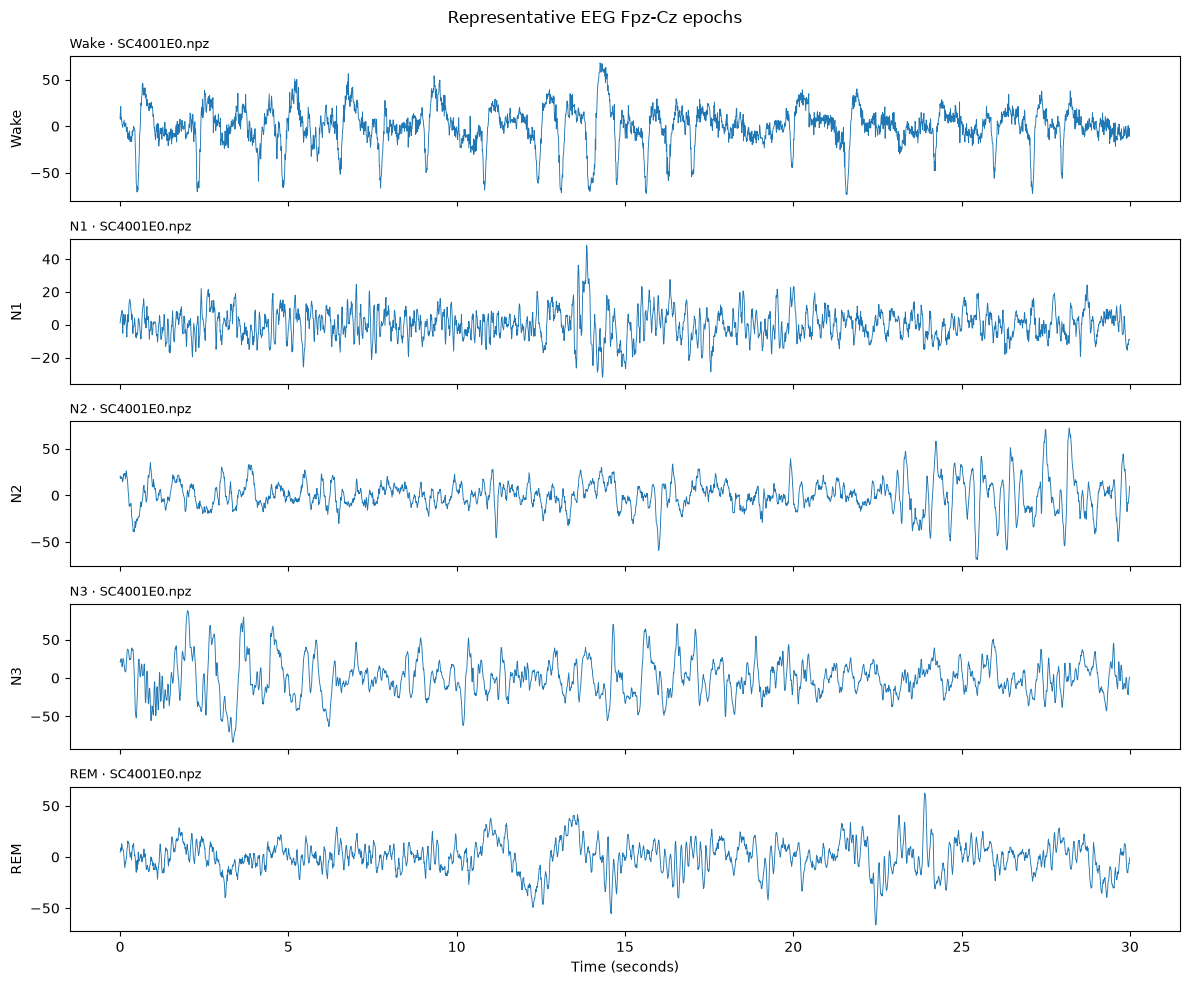

In [6]:
# Plot representative complete 30-second epochs, one for each measured stage.
example_by_stage = {}
for path in inventory["files"]:
    signal, codes, fs, channel = load_recording(path)
    for code_value in np.unique(codes):
        stage = LABEL_MAPPING[int(code_value)]
        if stage not in example_by_stage:
            example_by_stage[stage] = (signal[np.flatnonzero(codes == code_value)[0]], fs, path.name)
    if len(example_by_stage) == len(STAGE_ORDER):
        break
fig, axes = plt.subplots(len(STAGE_ORDER), 1, figsize=(12, 10), sharex=True)
for ax, stage in zip(axes, STAGE_ORDER):
    epoch, fs, source = example_by_stage[stage]
    ax.plot(np.arange(len(epoch)) / fs, epoch, lw=.65)
    ax.set_ylabel(stage)
    ax.set_title(f"{stage} · {source}", loc="left", fontsize=9)
axes[-1].set_xlabel("Time (seconds)")
fig.suptitle(f"Representative {channel} epochs")
fig.tight_layout()
plt.show()

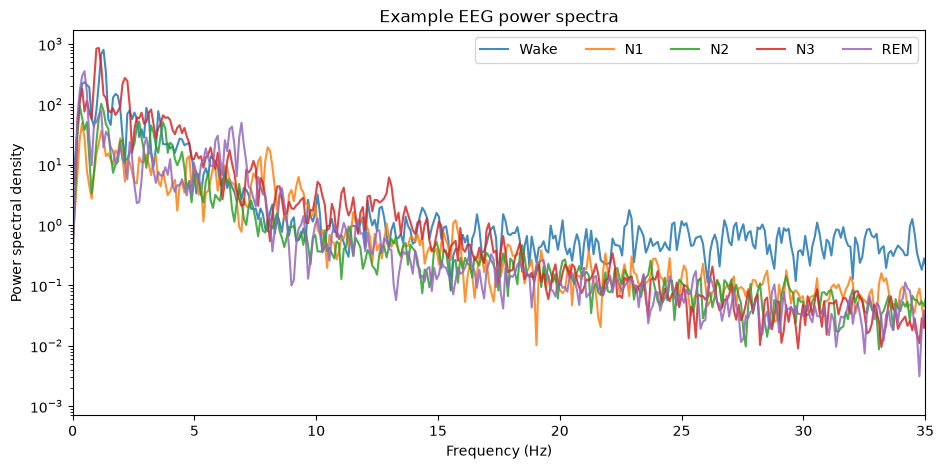

In [7]:
# Welch power spectrum of the example epochs.
fig, ax = plt.subplots(figsize=(11, 5))
for stage in STAGE_ORDER:
    epoch, fs, _source = example_by_stage[stage]
    freq, psd = welch(epoch, fs=fs, nperseg=1024)
    ax.semilogy(freq, psd, label=stage, alpha=.85)
ax.set(xlim=(0, 35), xlabel="Frequency (Hz)", ylabel="Power spectral density", title="Example EEG power spectra")
ax.legend(ncol=5)
plt.show()

## 4. Feature engineering

In [8]:
X, y, subject_groups, recording_ids = build_feature_dataset(DATA_DIR)
print("Feature matrix:", X.shape)
print("Target distribution:")
display(y.value_counts().reindex(STAGE_ORDER).rename("epochs").to_frame())
print("Feature names:", FEATURE_COLUMNS)
print("Non-finite features:", int((~np.isfinite(X.to_numpy())).sum()))

Feature matrix: (42308, 17)
Target distribution:


,epochs
sleep_stage,
Wake,8285
N1,2804
N2,17799
N3,5703
REM,7717


Feature names: ['signal_mean', 'signal_std', 'signal_rms', 'hjorth_mobility', 'hjorth_complexity', 'spectral_entropy', 'dominant_frequency', 'delta_absolute_power', 'delta_relative_power', 'theta_absolute_power', 'theta_relative_power', 'alpha_absolute_power', 'alpha_relative_power', 'sigma_absolute_power', 'sigma_relative_power', 'beta_absolute_power', 'beta_relative_power']
Non-finite features: 0


For each epoch, the shared `src.signal_processing` function extracts mean, standard deviation, RMS, Hjorth mobility and complexity, spectral entropy, dominant frequency, and absolute/relative power in delta, theta, alpha, sigma, and beta bands. These deterministic signal transforms happen per epoch; the learned imputer and scaler stay inside the model Pipeline and are fit only within each training fold.

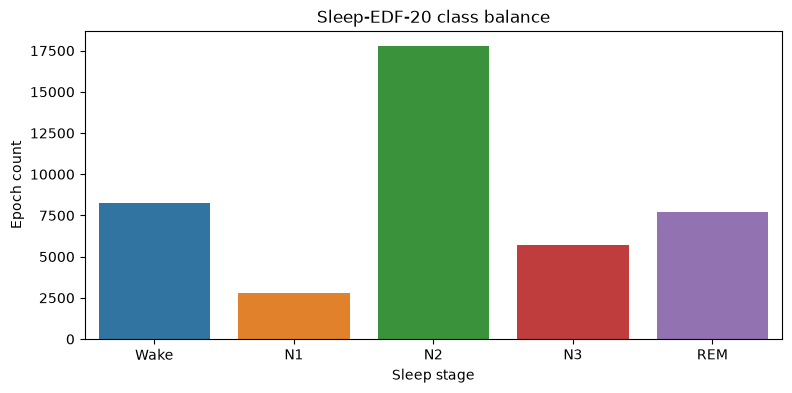

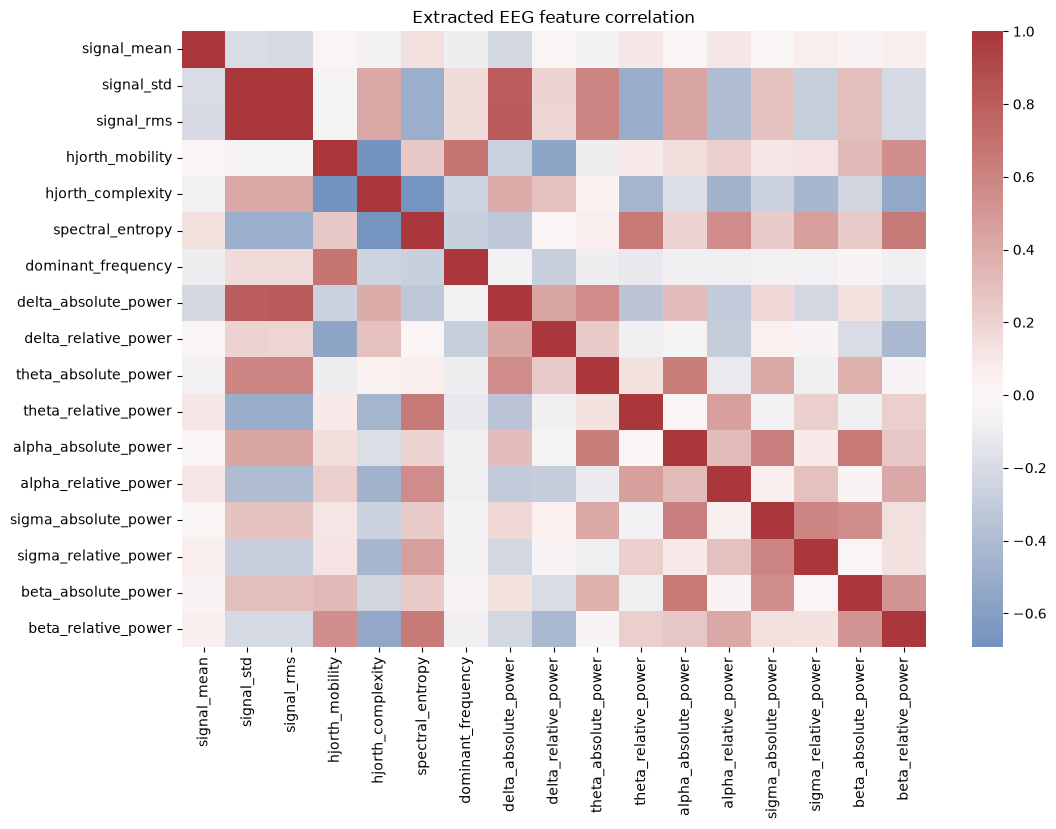

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=stage_counts.index, y=stage_counts.values, order=STAGE_ORDER, hue=stage_counts.index, legend=False, ax=ax)
ax.set(title="Sleep-EDF-20 class balance", xlabel="Sleep stage", ylabel="Epoch count")
plt.show()
fig, ax = plt.subplots(figsize=(12, 8))
corr = X.corr(numeric_only=True)
sns.heatmap(corr, cmap="vlag", center=0, ax=ax)
ax.set_title("Extracted EEG feature correlation")
plt.show()

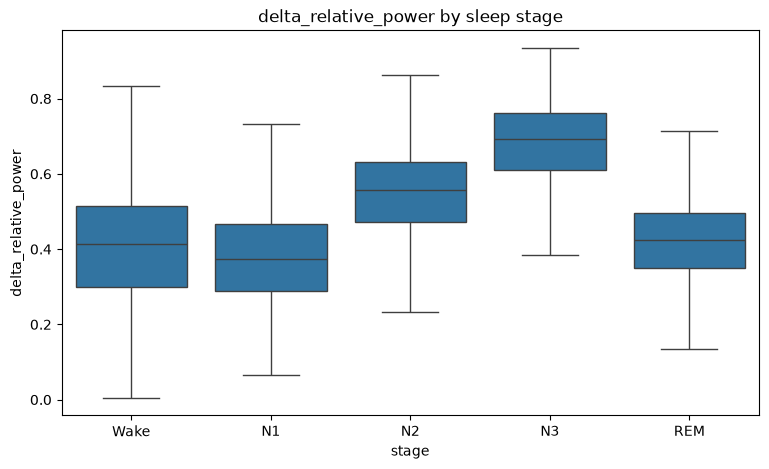

,signal_mean,signal_std,signal_rms,hjorth_mobility,hjorth_complexity,spectral_entropy,dominant_frequency,delta_absolute_power,delta_relative_power,theta_absolute_power,theta_relative_power,alpha_absolute_power,alpha_relative_power,sigma_absolute_power,sigma_relative_power,beta_absolute_power,beta_relative_power
stage,,,,,,,,,,,,,,,,,
Wake,-0.0250,23.4439,23.4820,0.5087,3.9423,5.7167,0.9325,287.4248,0.4101,32.5430,0.0714,11.9503,0.0348,6.9210,0.0138,22.4686,0.0424
N1,-0.0536,11.4800,11.5350,0.4571,3.5825,5.8491,0.6517,56.6332,0.3825,12.3516,0.1061,5.2057,0.0458,2.4818,0.0183,6.0316,0.0439
N2,-0.0905,16.0321,16.0757,0.3557,3.7687,5.6854,1.8553,147.5594,0.5416,21.9522,0.0930,6.8170,0.0296,8.6148,0.0398,2.8181,0.0128
N3,-0.3158,30.0795,30.1212,0.1922,5.6817,4.8359,1.0439,684.0964,0.6769,34.7470,0.0404,8.9055,0.0104,6.3496,0.0077,2.3589,0.0026
REM,-0.1526,12.0386,12.1262,0.4233,3.9198,5.7331,1.8183,60.9909,0.4175,15.0544,0.1193,4.1087,0.0344,1.8093,0.0144,3.4228,0.0278


In [10]:
feature_to_plot = "delta_relative_power"
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=X.assign(stage=y), x="stage", y=feature_to_plot, order=STAGE_ORDER, ax=ax, showfliers=False)
ax.set_title(f"{feature_to_plot} by sleep stage")
plt.show()
display(X.assign(stage=y).groupby("stage").mean(numeric_only=True).reindex(STAGE_ORDER).round(4))

## 5. Subject-independent partition

In [11]:
train_idx, test_idx, outer_splits = _subject_holdout(X, y, subject_groups, random_state=42)
train_subjects = sorted(subject_groups.iloc[train_idx].unique())
test_subjects = sorted(subject_groups.iloc[test_idx].unique())
print("Train subjects:", train_subjects)
print("Test subjects:", test_subjects)
print("Overlap:", sorted(set(train_subjects) & set(test_subjects)))
print("Train epochs:", len(train_idx), "Test epochs:", len(test_idx))
print("Test-stage counts:")
display(y.iloc[test_idx].value_counts().reindex(STAGE_ORDER).rename("epochs").to_frame())
assert not set(train_subjects) & set(test_subjects)

Train subjects: ['SC400', 'SC401', 'SC402', 'SC403', 'SC404', 'SC406', 'SC408', 'SC411', 'SC412', 'SC413', 'SC414', 'SC415', 'SC416', 'SC417', 'SC418', 'SC419']
Test subjects: ['SC405', 'SC407', 'SC409', 'SC410']
Overlap: []
Train epochs: 33708 Test epochs: 8600
Test-stage counts:


,epochs
sleep_stage,
Wake,1550
N1,613
N2,3979
N3,941
REM,1517


The subject-disjoint holdout is one fold of `StratifiedGroupKFold`; here it leaves four complete subjects for testing and 16 for training, with all five labels on both sides. Hyperparameter search uses four additional stratified grouped folds drawn only from the training subjects. A person ID is never passed as a predictive feature.

## 6. Train and tune the four ML-II models

In [12]:
# This call recomputes the deterministic features, tunes all four classifiers on training subjects only,
# evaluates the held-out subjects once, and writes the current Sleep-EDF artifacts under models/.
metrics = train_models(DATA_DIR, output_dir=MODEL_DIR, random_state=42)
print("Selected by training-only grouped CV macro F1:", metrics["best_model"])
print("Subject overlap:", metrics["subject_overlap"])

Selected by training-only grouped CV macro F1: Random Forest
Subject overlap: []


In [13]:
comparison = pd.DataFrame.from_dict(metrics["models"], orient="index").rename_axis("Model")
display(comparison[["accuracy", "precision_macro", "recall_macro", "f1_macro",
                    "cross_validation_f1_macro_mean", "cross_validation_f1_macro_std", "training_time_seconds"]]
        .sort_values("cross_validation_f1_macro_mean", ascending=False).round(4))
print("Best hyperparameters:")
for name, result in metrics["models"].items():
    print(name, result["best_params"])

,accuracy,precision_macro,recall_macro,f1_macro,cross_validation_f1_macro_mean,cross_validation_f1_macro_std,training_time_seconds
Model,,,,,,,
Random Forest,0.7853,0.7043,0.7319,0.7152,0.6858,0.0314,64.1721
SVM,0.7585,0.6424,0.6722,0.6523,0.6389,0.0295,1.9530
Logistic Regression,0.7291,0.6406,0.6768,0.6525,0.6356,0.0485,4.2849
Decision Tree,0.7260,0.6667,0.6963,0.6703,0.6336,0.0297,5.2049


Best hyperparameters:
Logistic Regression {'classifier__C': 0.1}
Decision Tree {'classifier__max_depth': 12, 'classifier__min_samples_leaf': 5}
Random Forest {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 3}
SVM {'classifier__C': 0.1}


## 7. Held-out test evaluation

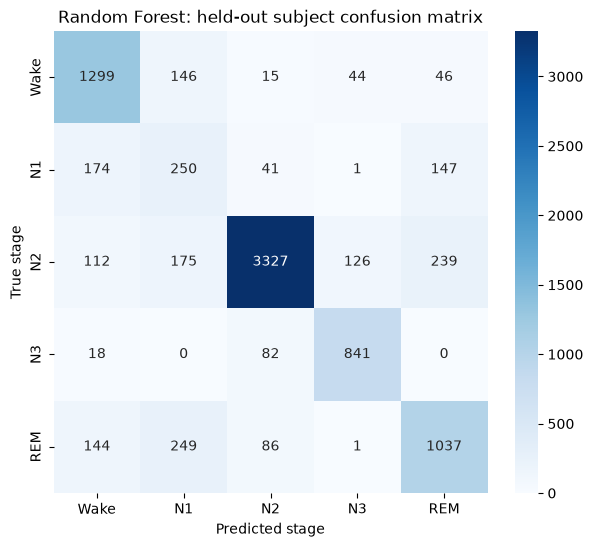

,precision,recall,f1-score,support
Wake,0.744,0.838,0.788,1550.000
N1,0.305,0.408,0.349,613.000
N2,0.937,0.836,0.884,3979.000
N3,0.830,0.894,0.861,941.000
REM,0.706,0.684,0.695,1517.000
accuracy,0.785,0.785,0.785,0.785
macro avg,0.704,0.732,0.715,8600.000
weighted avg,0.805,0.785,0.792,8600.000


In [14]:
best_name = metrics["best_model"]
best_result = metrics["models"][best_name]
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(np.asarray(best_result["confusion_matrix"]), annot=True, fmt="d", cmap="Blues",
            xticklabels=STAGE_ORDER, yticklabels=STAGE_ORDER, ax=ax)
ax.set(xlabel="Predicted stage", ylabel="True stage", title=f"{best_name}: held-out subject confusion matrix")
plt.show()
display(pd.DataFrame(best_result["classification_report"]).T.round(3))

,Model,CV macro F1 (train subjects),Test accuracy,Test macro precision,Test macro recall,Test macro F1
0,Logistic Regression,0.6356,0.7291,0.6406,0.6768,0.6525
1,Decision Tree,0.6336,0.7260,0.6667,0.6963,0.6703
2,Random Forest,0.6858,0.7853,0.7043,0.7319,0.7152
3,SVM,0.6389,0.7585,0.6424,0.6722,0.6523


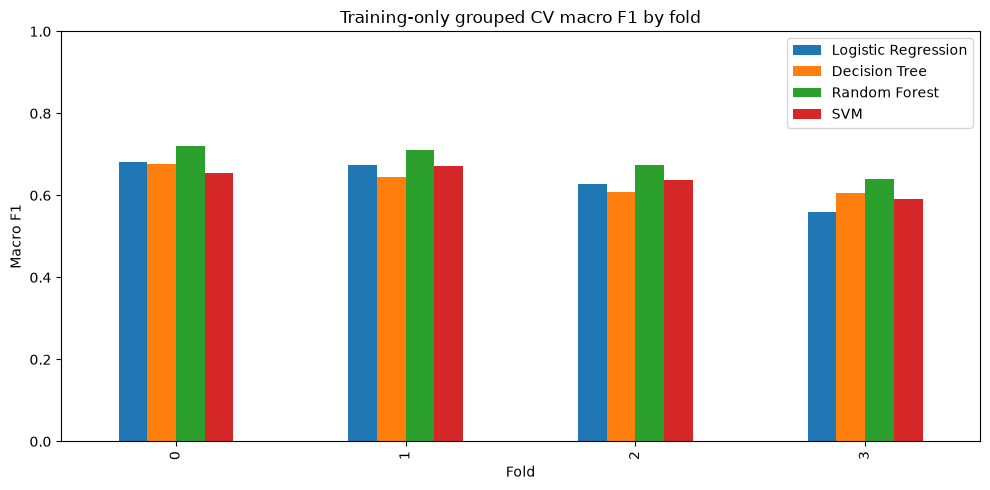

In [15]:
metric_rows = []
for name, result in metrics["models"].items():
    metric_rows.append({"Model": name, "CV macro F1 (train subjects)": result["cross_validation_f1_macro_mean"],
                        "Test accuracy": result["accuracy"], "Test macro precision": result["precision_macro"],
                        "Test macro recall": result["recall_macro"], "Test macro F1": result["f1_macro"]})
metric_table = pd.DataFrame(metric_rows)
display(metric_table.round(4))
fig, ax = plt.subplots(figsize=(10, 5))
cv_plot = pd.DataFrame({name: result["cross_validation_f1_macro"] for name, result in metrics["models"].items()})
cv_plot.plot(kind="bar", ax=ax)
ax.set(title="Training-only grouped CV macro F1 by fold", xlabel="Fold", ylabel="Macro F1", ylim=(0, 1))
plt.tight_layout()
plt.show()

,importance
alpha_absolute_power,0.031628
signal_mean,0.032435
alpha_relative_power,0.034314
theta_relative_power,0.038525
theta_absolute_power,0.039383
hjorth_complexity,0.040206
sigma_relative_power,0.060123
hjorth_mobility,0.062390
signal_rms,0.070004
signal_std,0.070446


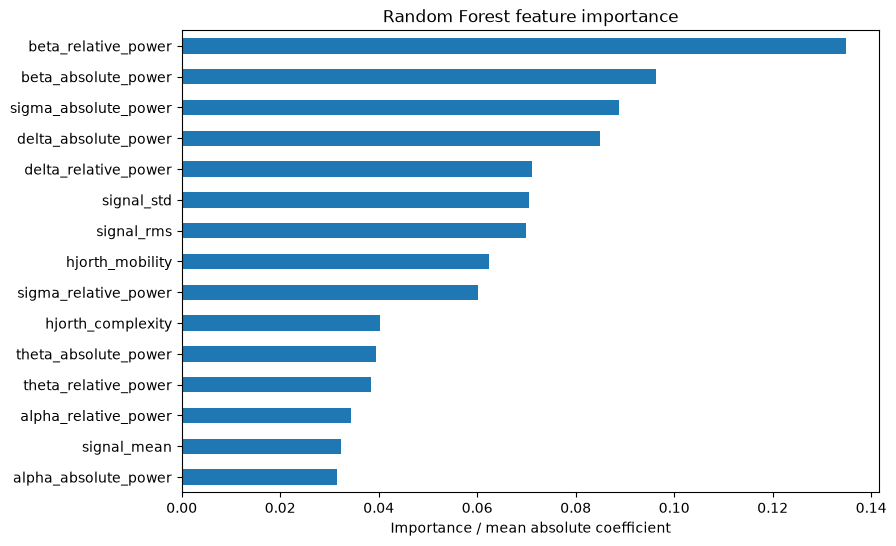

In [16]:
importance = metrics["feature_importance"].get(best_name, {})
if importance:
    importance_frame = pd.Series(importance).sort_values(ascending=False).head(15).sort_values()
    display(importance_frame.rename("importance").to_frame())
    importance_frame.plot.barh(figsize=(9, 6), title=f"{best_name} feature importance")
    plt.xlabel("Importance / mean absolute coefficient")
    plt.show()
else:
    print("No built-in feature importance for this classifier.")

## 8. Saved-model prediction demonstration

In [17]:
bundle = __import__("src.prediction", fromlist=["load_model"]).load_model(MODEL_DIR / "sleep_stage_model.joblib")
heldout_epoch = X.iloc[test_idx[:1]]
# The saved bundle uses the same feature order and fitted pipeline as training.
predicted = bundle["model"].predict(heldout_epoch)[0]
print("True stage:", y.iloc[test_idx[0]])
print("Predicted stage:", predicted)
print("Loaded artifact model:", bundle["model_name"])

True stage: Wake
Predicted stage: Wake
Loaded artifact model: Random Forest


## 9. Conclusions and limitations

- Sleep-EDF-20 provides single-channel Fpz-Cz signals at 100 Hz, split into labeled 30-second epochs. The local archive contains 42,308 epochs from 20 subjects and all five target classes.
- Stage counts are imbalanced, especially N1; report macro metrics and per-stage recall alongside accuracy.
- The held-out evaluation is subject-independent, but the test set contains only four subjects. Results can vary with the subject split and should not be treated as clinical performance.
- The model classifies independent epochs from engineered features and does not use neighboring-epoch sequence context. Uploaded predictions require the same preprocessed NPZ format and 100 Hz/3,000-sample epochs.
- The final model was selected by training-only grouped CV macro F1; test results were used only for final reporting.

Saved artifacts: `models/sleep_stage_model.joblib`, four classifier pipelines, `models/metrics.json`, and `models/model_comparison.csv`.